# Firms over time: ownership chains, health systems and the claims filter

`provider_networks.ipynb` builds the graph out of one-hop edges: a practitioner reassigns to an organization, an organization's hospital enrollment matches a CCN. Health systems are not one hop. A hospital, the holding company that owns it, the parent that owns the holding company, the parent's nursing homes and the physician group billing under the parent's tax id are one firm, and none of the PPEF, NPPES and POS files says so. This notebook adds the public files that do, and replicates the studies that used them:

| Section | Paper | Source added | Result |
|---|---|---|---|
| 1 | ASPE, hospital chains by ultimate owner (Welch, Xu, De Lew and Sommers 2023) | CMS All Owners files, monthly from 2022 | **Replicates.** 256 chains of three or more holding 56.5% of hospitals, against ASPE's 243 and 56.1%; the eleven largest chains in ASPE's order, each within six hospitals. Extended monthly, the share rises to 59.6% by September 2026. |
| 2 | ASPE, nursing home chains (Welch, Oliveira, Blanco and Sommers 2023) | CMS SNF Enrollments files | **Exact.** The ten largest chains to the facility (Genesis 237 ... Signature 101) and every size band within two SNFs. ASPE's ultimate-owner method, run on the SNF owner files, agrees with CMS's chains on 84 to 89% of the pairs it makes and finds half of CMS's pairs. |
| 3 | AHRQ Compendium of U.S. Health Systems, as the benchmark for systems after 2023 | the graph's firms (`firm`, `firm_member`) | **Firms are as precise as ASPE's chains and find more.** Against AHRQ's 2022 and 2023 systems, 69 to 70% of the hospital pairs a firm makes are in one AHRQ system (chains 68 to 69%), and firms find 45 to 54% of AHRQ's pairs (chains 43 to 50%). Firm ids carry over between quarters, so acquisitions appear as dated merges: UnitedHealth absorbing Amedisys in 2025, PACS absorbing Providence Group in 2024. |
| 4 | Luo et al. (2024), hospital-related tax ids: basic, network and name steps; Neprash et al. (2015), service location | firms; Medicare Physician & Other Practitioners by Provider and Service | **Still a floor.** The network and name steps add 0.7 points before 2022 and 4.1 by 2026 (18.3% basic, 22.4% with both), against Luo et al.'s 43.5% in 2019. The service location measure puts 12% of physicians in hospital settings, and the two measures agree on a third of each other's integrated physicians, as Luo et al. found (38%). |
| 5 | Muhlestein and Smith (2016) on their own data; MD-PPAS as the scorecard for group weights | archived Physician Compare (Doctors and Clinicians) files, 2014-2022 | **Reproduces within a point.** The November 2015 file gives 34.4% of physicians in groups of 100 or more and 36.0% in groups of nine or fewer, against Muhlestein and Smith's December 2015 figures of 35.1 and 35.3. On the PPEF graph, weighting each physician over the groups Physician Compare lists cuts the error per tax id against MD-PPAS by 10 to 25%. |

Every table here is a dated history. The sources are versioned like the rest of the warehouse (docs/METHODOLOGY.md sections 7a and 7b), and the graph's firms, chains and claims-filtered pairs are interval tables on its quarterly clock (sections 8d and 8e), so each result below can be recomputed as of any date the files cover, and a firm can be followed through its acquisitions.

## 0. Open the export and the graph

The ownership and Doctors and Clinicians tables are in the export (`$LEDGER_EXPORT`, default the repository's `export/`); the firms, chains, claims-filtered pairs and weights are in the graph (`$LEDGER_GRAPH`), built with

```bash
uv run healthcare-ledger graph-build --out graph --compendium --medicaid --ownership --doctors-clinicians --medicare-utilization
```

`ownership_snapshots` lists the releases of the ownership files: hospitals and nursing homes monthly, the other four facility types quarterly.

In [1]:
import json, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import healthcare_ledger
from healthcare_ledger.derived import firms
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

EXPORT = Path(os.environ.get("LEDGER_EXPORT", "../../export")).resolve()
GRAPH = Path(os.environ.get("LEDGER_GRAPH", "../../graph")).resolve()
manifest = json.load(open(GRAPH / "manifest.json"))
print("graph built", manifest["generated_at"], "|", manifest["quarters"], "quarters", manifest["first_as_of_date"], "to",
      manifest["last_as_of_date"], "| ownership from", manifest.get("ownership", {}).get("first_release"),
      "| Doctors and Clinicians vintages", len(manifest.get("doctors_clinicians", {}).get("vintages", [])))
con = healthcare_ledger.connect(EXPORT, GRAPH)     # a view per table of the export and of the graph


def asof(table, d):
    """The rows of an interval table in force on date d."""
    return f"(SELECT * FROM {table} WHERE effective_date <= DATE '{d}' AND (end_date IS NULL OR end_date > DATE '{d}'))"


releases = con.sql("""SELECT as_of_date, string_split(streams_present, ',') AS streams FROM ownership_snapshots
                      ORDER BY 1""").df()
releases.assign(n_files=releases.streams.str.len()).drop(columns="streams").T

graph built 2026-10-28T13:04:01 | 43 quarters 2016-02-01 to 2026-09-29 | ownership from 2022-09-20 | Doctors and Clinicians vintages 46


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52
as_of_date,2022-09-20 00:00:00,2022-10-31 00:00:00,2022-11-21 00:00:00,2022-11-28 00:00:00,2022-11-30 00:00:00,2022-12-30 00:00:00,2023-01-01 00:00:00,2023-02-01 00:00:00,2023-03-10 00:00:00,2023-03-31 00:00:00,2023-05-01 00:00:00,2023-06-01 00:00:00,2023-07-06 00:00:00,2023-08-01 00:00:00,2023-09-01 00:00:00,...,2025-07-01 00:00:00,2025-08-01 00:00:00,2025-09-01 00:00:00,2025-10-01 00:00:00,2025-11-06 00:00:00,2025-12-02 00:00:00,2026-01-02 00:00:00,2026-01-21 00:00:00,2026-02-02 00:00:00,2026-03-02 00:00:00,2026-04-01 00:00:00,2026-05-01 00:00:00,2026-07-17 00:00:00,2026-07-31 00:00:00,2026-09-29 00:00:00
n_files,2,2,1,1,2,3,1,4,4,8,4,4,8,4,4,...,12,4,4,12,4,4,8,4,4,4,12,4,12,4,12


## 1. Hospital chains: replicating ASPE (Welch et al. 2023)

When CMS first published the hospital All Owners file, ASPE (HP-2023-14) built chains from it. PECOS lists every direct and indirect owner of 5% or more of a hospital's legal entity, by the owner's own associate id, but not which owner is at the top. ASPE's method: keep the owners with more than half of a hospital or an unreported share; the owner of the most hospitals is an ultimate owner, since an ultimate owner owns everything its subsidiaries do; its hospitals form a chain and leave the working file; repeat until the next owner would own two. A hospital with no owner of record is owned by its own legal entity, which puts multi-hospital legal entities such as Kaiser Foundation Hospitals in chains.

ASPE's working file has 4,644 hospitals: the 7,272 enrollments of the file less 2,305 special units (psychiatric, rehabilitation and swing-bed units, which share their hospital's legal entity), 37 duplicate CCNs, 27 critical access hospitals and 259 ambulatory surgery centers and free-standing emergency departments enrolled as hospitals during the public health emergency. The first three are rules on the CCN: a unit has a letter in the third place, a critical access hospital is 1300-1399, and the 37 duplicates are exactly the transplant-center CCNs (`xx98xx`), which repeat a hospital. ASPE did not publish its list of the 259; the cell below finds them by name (surgery centers and Texas emergency rooms), a stated substitute that catches 204 of them.

The chains are the graph's own code (`derived/firms.py`, `chains`), run on the release ASPE used, the file dated 28 November 2022.

In [2]:
# ASPE's working file: hospital enrollments without the special units (a letter in the CCN's third place), the
# critical access hospitals (CCN 1300-1399), the transplant-center CCNs (xx98xx, which repeat a hospital) and, as a
# stated substitute for ASPE's unpublished list, the ambulatory surgery centers and free-standing emergency
# departments enrolled as hospitals during the public health emergency, found by name
WORKING = r"""
    facility_type = 'hospital' AND ccn IS NOT NULL AND substr(ccn, 3, 1) ~ '[0-9]'
    AND try_cast(substr(ccn, 3, 4) AS INT) NOT BETWEEN 1300 AND 1399 AND substr(ccn, 3, 2) <> '98'
    AND NOT (regexp_matches(upper(coalesce(name, '')), '(EMERGENCY|\bER\b)')
             AND NOT regexp_matches(upper(coalesce(name, '')), 'HOSPITAL|MEDICAL CENTER'))
    AND NOT (regexp_matches(upper(coalesce(name, '')), '(SURGERY CENTER|SURGICAL CENTER|SURGICENTER|SURGERY CTR|\bASC\b|ENDOSCOPY|SURGICAL ARTS|SURGERY & LASER|EYE SURGERY)')
             AND NOT regexp_matches(upper(coalesce(name, '')), 'HOSPITAL'))"""


def aspe_chains(d, types=("hospital",), working=WORKING):
    """ASPE's chains on release date d: the graph's own rule (derived/firms.py chains) over the release's enrollments
    and owners, after the working-file filter."""
    for name, sql in firms.quarter_sql(d).items():
        con.execute(f"CREATE OR REPLACE TEMP TABLE {name} AS {sql}")
    con.execute(f"DELETE FROM fenr WHERE facility_type IN {tuple(types) + ('',)} AND NOT ({working})")
    n = con.execute(f"SELECT count(DISTINCT ccn) FROM fenr WHERE facility_type IN {tuple(types) + ('',)}").fetchone()[0]
    return n, con.sql(firms.chains(con, types, "chain")).df()


n_hosp, ch = aspe_chains("2022-11-28")
bands = [(50, "50 or more"), (25, "25-49"), (10, "10-24"), (7, "7-9"), (5, "5-6"), (3, "3-4")]
def band(n): return next(b for lo, b in bands if n >= lo)
t2 = (ch.groupby("chain_owner_pac_id").agg(n=("ccn", "count")).assign(band=lambda x: x.n.map(band))
        .groupby("band").agg(chains=("n", "size"), hospitals=("n", "sum")).reindex([b for _, b in bands]))
t2.loc["total"] = t2.sum()
t2["pct_of_hospitals"] = 100 * t2.hospitals / n_hosp
t2["aspe_chains"] = [9, 10, 36, 42, 44, 102, 243]
t2["aspe_hospitals"] = [841, 331, 509, 329, 241, 352, 2603]
print("working file:", n_hosp, "hospitals (ASPE: 4,644)")
t2.round(1)

working file: 4701 hospitals (ASPE: 4,644)


,chains,hospitals,pct_of_hospitals,aspe_chains,aspe_hospitals
band,,,,,
50 or more,9,854,18.2,9,841
25-49,10,334,7.1,10,331
10-24,33,473,10.1,36,509
7-9,45,356,7.6,42,329
5-6,45,247,5.3,44,241
3-4,114,390,8.3,102,352
total,256,2654,56.5,243,2603


In [3]:
aspe_t3 = pd.DataFrame({"aspe": [152, 147, 122, 107, 74, 66, 63, 58, 52, 47, 44]},
                       index=["HCA", "UNIVERSAL", "ENCOMPASS", "SELECT", "COMMUNITY", "LIFEPOINT", "KNIGHT", "COMMONSPIRIT",
                              "TENET", "ACADIA", "TRINITY"])
top = ch.groupby(["chain_owner_pac_id", "chain_name"]).size().sort_values(ascending=False).head(12).reset_index(name="hospitals")
top["aspe"] = [next((v for k, v in aspe_t3.aspe.items() if str(n).upper().split()[0].strip(",.") == k), None) for n in top.chain_name]
top

,chain_owner_pac_id,chain_name,hospitals,aspe
0,0446167381,"HCA, INC.",151,152.0
1,6800704727,UNIVERSAL HEALTH SERVICES INC,150,147.0
2,1850208828,ENCOMPASS HEALTH CORPORATION,123,122.0
3,1759298748,SELECT MEDICAL CORPORATION,113,107.0
4,2567379332,COMMUNITY HEALTH SYSTEMS INC,74,74.0
5,4880725506,LIFEPOINT HEALTH INC,68,66.0
6,5395139273,"KNIGHT HEALTH HOLDINGS, LLC",64,63.0
7,1355259755,COMMONSPIRIT HEALTH,57,58.0
8,0547178105,TENET HEALTHCARE CORPORATION,54,52.0
9,3577734599,ACADIA HEALTHCARE COMPANY INC,47,47.0


**The chains replicate.** With a working file of 4,701 hospitals (ASPE: 4,644; the gap is mostly the 55 emergency rooms and surgery centers the name rule does not catch), 256 chains of three or more hold 56.5% of hospitals, against ASPE's 243 chains and 56.1%. The 50-or-more band matches in count (9 chains) and within 13 hospitals; the smaller bands differ by a few chains each, most in the 3-4 band (114 against 102), where a hospital or two more or less moves a chain across the threshold. The eleven largest chains come out in ASPE's order and within six hospitals of ASPE's counts, the largest gap Select Medical (113 against 107). ASPE resolved by hand the few hospitals its procedure assigned to two chains; the code here assigns each to the first chain that claims it.

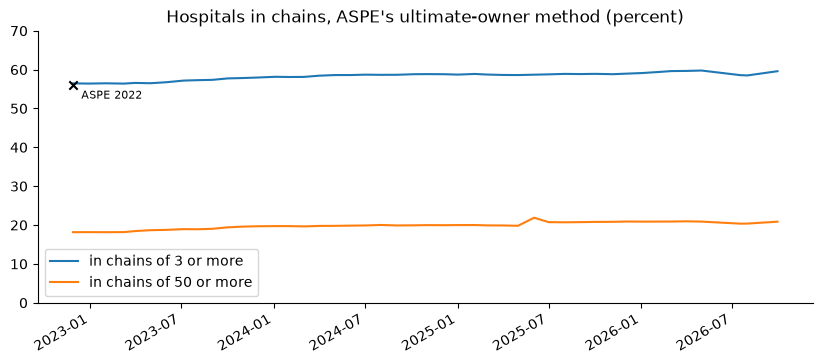

,hospitals,chains,pct_in_chains,pct_in_50_plus
release,,,,
2022-11-28,4701,256,56.5,18.2
2023-07-06,4635,252,57.2,18.9
2023-08-01,4632,253,57.3,18.9
2024-08-01,4656,253,58.7,20.0
2025-08-01,4637,255,58.9,20.7
2026-09-29,4630,254,59.6,20.9


In [4]:
# every hospital release, September 2022 to September 2026: the share of the working file in chains of 3 or more,
# the number of chains, and the share in chains of 50 or more
hosp_releases = [str(d.date()) for d, s in zip(releases.as_of_date, releases.streams) if "ownership_hospital_owner" in s]
rows = []
for d in hosp_releases:
    n, c = aspe_chains(d)
    size = c.groupby("chain_owner_pac_id").ccn.transform("count")
    rows.append({"release": pd.Timestamp(d), "hospitals": n, "chains": c.chain_owner_pac_id.nunique(),
                 "pct_in_chains": 100 * len(c) / n, "pct_in_50_plus": 100 * (size >= 50).sum() / n})
hosp_chains = pd.DataFrame(rows).set_index("release")
ax = hosp_chains[["pct_in_chains", "pct_in_50_plus"]].rename(columns={
    "pct_in_chains": "in chains of 3 or more", "pct_in_50_plus": "in chains of 50 or more"}).plot(title="Hospitals in chains, ASPE's ultimate-owner method (percent)")
ax.scatter([pd.Timestamp("2022-11-28")], [56.1], marker="x", color="k", zorder=5)
ax.annotate("ASPE 2022", (pd.Timestamp("2022-11-28"), 56.1), textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel(""); ax.set_ylim(0, 70); plt.show()
hosp_chains.iloc[[0, 7, 8, 20, 32, -1]].round(1)

**Extended monthly, chains keep growing their share while their number holds.** Between November 2022 and September 2026 the share of hospitals in chains of three or more rises from 56.5 to 59.6%, and in chains of 50 or more from 18.2 to 20.9%, while the number of chains stays between 252 and 256 and the working file loses 71 hospitals. The July 2023 file is the first with critical access hospitals; the working file leaves them out, as ASPE's does, so the series has no step there.

## 2. Nursing home chains: replicating ASPE (Welch, Oliveira, Blanco and Sommers 2023)

For nursing homes ASPE did not infer chains: the SNF Enrollments file carries an *affiliated entity*, CMS's own grouping of nursing homes under common ownership or operation, which ASPE's brief on the September 2022 file reports as chains: 14,810 SNFs, 607 chains, two thirds of SNFs in one.

In [5]:
snf = con.sql(f"""SELECT * FROM {asof('medicare_facility_enrollment', '2022-09-20')} WHERE facility_type = 'snf'""")
aff = con.sql("""
WITH c AS (SELECT affiliation_entity_id, any_value(affiliation_entity_name) AS name, count(DISTINCT ccn) AS n
           FROM snf WHERE affiliation_entity_id IS NOT NULL GROUP BY 1)
SELECT CASE WHEN n > 100 THEN '>100' WHEN n > 50 THEN '51-100' WHEN n > 25 THEN '26-50' WHEN n > 10 THEN '11-25' ELSE '2-10' END AS size,
       count(*) AS chains, sum(n) AS snfs
FROM c GROUP BY 1 ORDER BY min(n) DESC""").df().set_index("size")
total = con.sql("SELECT count(DISTINCT ccn) FROM snf").fetchone()[0]
aff.loc["not assigned"] = [None, total - aff.snfs.sum()]
aff["pct"] = 100 * aff.snfs / total
aff["aspe_snfs"] = [1557, 1171, 2460, 2456, 2153, 5013]
print(total, "SNFs (ASPE: 14,810)")
aff.round(1)

14864 SNFs (ASPE: 14,810)


,chains,snfs,pct,aspe_snfs
size,,,,
>100,10.0,1557.0,10.5,1557
51-100,17.0,1172.0,7.9,1171
26-50,70.0,2460.0,16.6,2460
11-25,159.0,2458.0,16.5,2456
2-10,350.0,2153.0,14.5,2153
not assigned,NaN,5064.0,34.1,5013


In [6]:
con.sql("""SELECT any_value(affiliation_entity_name) AS chain, count(DISTINCT ccn) AS snfs, count(DISTINCT state) AS states
           FROM snf WHERE affiliation_entity_id IS NOT NULL GROUP BY affiliation_entity_id ORDER BY 2 DESC LIMIT 10""").df()

,chain,snfs,states
0,GENESIS HEALTHCARE,237,22
1,THE ENSIGN GROUP,234,13
2,LIFE CARE CENTERS OF AMERICA,210,29
3,HCR MANORCARE,155,15
4,PROVIDENCE GROUP,130,7
5,CONSULATE HEALTH CARE/INDEPENDENCE LIVING CENT...,128,6
6,EVANGELICAL LUTHERAN GOOD SAMARITAN SOCIETY,126,22
7,TRILOGY HEALTH SERVICES,124,6
8,SABER HEALTHCARE GROUP,112,7
9,SIGNATURE HEALTHCARE,101,10


**The tables reproduce exactly.** The September 2022 file lists 14,864 SNFs (ASPE: 14,810, after dropping some it does not describe), 606 affiliated entities (607), and the same ten largest chains with the same counts. Every size band matches within two SNFs; the unassigned SNFs are 51 more than ASPE's, nearly the 54 by which the totals differ. The affiliated entity ids themselves are renumbered by CMS most months (docs/METHODOLOGY.md section 7a), so a chain is followed by its members, not its id; the share of SNFs in a CMS chain rises from 65.9% in September 2022 to 70.4% in September 2026.

In [7]:
# ASPE's ultimate-owner rule on nursing homes, scored against CMS's affiliated entities, release by release: a pair of
# SNFs is a true positive when both methods put them together. Precision is the share of the owner-method pairs CMS
# also pairs; recall the share of CMS's pairs the owner method finds
def pair_scores(df, truth, pred):
    """Pairwise precision and recall of the clustering `pred` against `truth` (NULL = unclustered)."""
    pairs = lambda g: (g.groupby(g.columns.tolist()).size() * (g.groupby(g.columns.tolist()).size() - 1) / 2).sum()
    both = df.dropna(subset=[truth, pred])
    tp = pairs(both[[truth, pred]])
    return tp / pairs(df.dropna(subset=[pred])[[pred]]), tp / pairs(df.dropna(subset=[truth])[[truth]])

snf_releases = [str(d.date()) for d, s in zip(releases.as_of_date, releases.streams)
                if "ownership_snf_owner" in s and "ownership_snf_enrollment" in s]
rows = []
for d in snf_releases:
    n, c = aspe_chains(d, ("snf",), "facility_type = 'snf'")
    truth = con.sql(f"""SELECT ccn, any_value(affiliation_entity_id) AS cms FROM {asof('medicare_facility_enrollment', d)}
                        WHERE facility_type = 'snf' AND ccn IS NOT NULL GROUP BY 1""").df()
    j = truth.merge(c[["ccn", "chain_owner_pac_id"]], on="ccn", how="left")
    p, r = pair_scores(j, "cms", "chain_owner_pac_id")
    rows.append({"release": pd.Timestamp(d), "snfs": n, "pct_in_cms_chain": 100 * j.cms.notna().mean(),
                 "pct_in_owner_chain": 100 * j.chain_owner_pac_id.notna().mean(), "pair_precision": 100 * p,
                 "pair_recall": 100 * r})
snf_chains = pd.DataFrame(rows).set_index("release")
snf_chains.iloc[[0, 1, 12, 24, 36, -1]].round(1)

,snfs,pct_in_cms_chain,pct_in_owner_chain,pair_precision,pair_recall
release,,,,,
2022-09-20,14864,65.9,48.9,89.2,54.9
2022-10-31,14843,65.9,48.9,88.8,54.7
2023-11-01,14641,64.0,50.1,83.5,51.9
2024-12-05,14509,67.2,50.7,86.2,51.3
2025-12-02,14437,68.8,49.2,84.9,47.3
2026-09-29,14404,70.4,47.9,84.4,43.3


CMS's affiliated entities are an independent grouping of the same facilities, made by CMS from more than the owner file. That makes them a truth set for the ownership method of section 1, which the graph's firms (section 3) build on.

**Ownership finds CMS's chains precisely but incompletely.** Of the SNF pairs the ultimate-owner method puts in one chain, 84 to 89% are in one CMS chain in every release; of CMS's pairs it finds 55% in 2022, falling to 43% by 2026. CMS's affiliated entities also group facilities by operator and management company, which the owner file records as managing parties rather than owners, and the share of SNFs CMS puts in a chain grows while the share the owner method does stays near half.

## 3. Firms: systems as transitive components

The graph's `firm` table (docs/METHODOLOGY.md section 8d) extends section 1's rule from chains to firms. Each controlled legal entity hangs from one ultimate owner, the owner that reaches the most facilities, over all six facility types at once; a firm is a connected component of those edges and of CMS's enrollment → CCN edges, so the links are transitive across any number of holding companies and across facility types, and a physician group whose associate id is a firm's legal entity or controlling owner is in the firm. Firm ids are carried over between quarters, so a firm is a dated history: it keeps its id as members come and go, and an acquisition closes the acquired firm's rows.

AHRQ's Compendium lists health systems through 2023 and assigns hospitals to them from AHA, IRS Form 990 Schedule R and its own research. The graph's firms are scored against it pair by pair: of the pairs of hospitals the firms put together, the share AHRQ also puts in one system (precision), and of AHRQ's pairs, the share the firms find (recall). ASPE's chains are scored the same way. A firm of one facility is no clustering and counts as unassigned.

In [8]:
quarters_own = con.sql("SELECT as_of_date FROM quarters WHERE n_firm IS NOT NULL ORDER BY 1").df().as_of_date.astype(str).tolist()
def firm_scores(d, year):
    """Hospitals AHRQ lists in year `year`: pairwise precision and recall of the graph's firms and of ASPE chains on
    graph quarter d against AHRQ's systems."""
    j = con.sql(f"""
        SELECT s.node_id AS ccn, s.health_sys_id AS ahrq, f.firm_id, c.chain_owner_pac_id AS chain
        FROM system_link s
        LEFT JOIN {asof('firm_member', d)} f ON f.node_type = 'ccn' AND f.node_id = s.node_id
        LEFT JOIN {asof('chain', d)} c ON c.chain_type = 'hospital' AND c.ccn = s.node_id
        WHERE s.year = {year} AND s.node_type = 'hospital'""").df()
    # a firm of one facility is no clustering
    j.loc[j.groupby("firm_id").ccn.transform("count") == 1, "firm_id"] = None
    out = {"quarter": d, "ahrq_year": year, "hospitals": len(j), "in_firm": int(j.firm_id.notna().sum())}
    for lbl in ("firm_id", "chain"):
        p, r = pair_scores(j, "ahrq", lbl)
        out[f"{lbl}_precision"], out[f"{lbl}_recall"] = 100 * p, 100 * r
    return out
# the first quarters with the hospital files (December 2022) and the middle of 2023, the Compendium's last year
pd.DataFrame([firm_scores(d, y) for d, y in (("2022-12-30", 2022), ("2023-07-06", 2023))]).round(1)

,quarter,ahrq_year,hospitals,in_firm,firm_id_precision,firm_id_recall,chain_precision,chain_recall
0,2022-12-30,2022,6632,2946,68.6,45.0,68.0,42.6
1,2023-07-06,2023,6676,3530,69.8,53.5,69.2,49.9


**Firms are as precise as chains and find more of AHRQ's systems.** On the hospitals AHRQ lists, 68.6% (2022) and 69.8% (2023) of the pairs a firm makes are in one AHRQ system, the same as ASPE's chains (68.0 and 69.2%), and firms find 45.0 and 53.5% of AHRQ's pairs against the chains' 42.6 and 49.9%: a firm adds the chains of two or fewer hospitals, the hospitals owned through a post-acute parent, and the hospitals joined by a shared legal entity. The 2022 quarter is the first with the hospital files, and AHRQ's 2022 edition describes the year before; 2023 is the fairer comparison. Most of the disagreement is the definition: AHRQ counts a system by common ownership or management through any channel (affiliations, management contracts, Form 990 Schedule R), the firms only by the 5%-or-more owners PECOS records.

The same firms against CMS's nursing home chains, quarter by quarter:

In [9]:
# the same firms scored against CMS's own nursing home chains, every quarter
rows = []
for d in quarters_own:
    j = con.sql(f"""
        SELECT e.ccn, any_value(e.affiliation_entity_id) AS cms, any_value(f.firm_id) AS firm_id
        FROM {asof('medicare_facility_enrollment', d)} e
        LEFT JOIN {asof('firm_member', d)} f ON f.node_type = 'ccn' AND f.node_id = e.ccn
        WHERE e.facility_type = 'snf' AND e.ccn IS NOT NULL GROUP BY 1""").df()
    j.loc[j.groupby("firm_id").ccn.transform("count") == 1, "firm_id"] = None
    p, r = pair_scores(j, "cms", "firm_id")
    rows.append({"quarter": d, "snfs": len(j), "firm_precision": 100 * p, "firm_recall": 100 * r})
pd.DataFrame(rows).set_index("quarter").round(1)

,snfs,firm_precision,firm_recall
quarter,,,
2022-09-30,14864,88.3,55.3
2022-12-30,14815,88.0,53.9
2023-03-31,14768,85.4,53.7
2023-07-06,14717,82.6,53.0
2023-10-02,14652,81.6,53.0
2024-01-05,14611,81.0,51.5
2024-04-01,14568,82.0,52.0
2024-07-01,14548,84.6,52.0
2024-10-07,14529,83.8,51.4


### Firms as a ledger

A firm id that ends has either dissolved or been absorbed. Following its members to the firm they are in on the quarter it ends gives the acquisitions the ownership files record, dated to the quarter:

In [10]:
# firms as a ledger: every firm id with its first and last quarter, and where the members of a firm that ended went
firm_life = con.sql("""
SELECT firm_id, min(effective_date) AS first_quarter, max(coalesce(end_date, DATE '9999-12-31')) AS ended,
       max(n_hospitals) AS max_hospitals, max(n_facilities) AS max_facilities, arg_max(name, effective_date) AS name
FROM firm GROUP BY 1""").df()
absorbed = con.sql("""
WITH ended AS (SELECT firm_id, max(end_date) AS end_date FROM firm GROUP BY 1 HAVING bool_and(end_date IS NOT NULL)),
before AS (SELECT m.node_type, m.node_id, m.firm_id, e.end_date FROM firm_member m JOIN ended e USING (firm_id)
           WHERE m.end_date = e.end_date),
after AS (SELECT b.firm_id AS old_firm, b.end_date, a.firm_id AS new_firm, count(*) AS members
          FROM before b JOIN firm_member a ON a.node_type = b.node_type AND a.node_id = b.node_id
           AND a.effective_date = b.end_date
          GROUP BY 1, 2, 3)
SELECT a.end_date AS quarter, a.old_firm, o.name AS old_name, a.new_firm, n.name AS new_name, a.members,
       o.n_facilities AS old_facilities
FROM after a
JOIN firm o ON o.firm_id = a.old_firm AND o.end_date = a.end_date
JOIN firm n ON n.firm_id = a.new_firm AND n.effective_date <= a.end_date AND (n.end_date IS NULL OR n.end_date > a.end_date)
WHERE a.old_firm <> a.new_firm AND o.n_facilities >= 5
ORDER BY o.n_facilities DESC""").df()
print(f"{len(firm_life):,} firm ids; {int((firm_life.max_facilities >= 3).sum()):,} ever with 3 or more facilities")
absorbed.head(15)

444,324 firm ids; 4,412 ever with 3 or more facilities


,quarter,old_firm,old_name,new_firm,new_name,members,old_facilities
0,2025-10-01,Fccn:017014,AMEDISYS INC,Fccn:190002,UNITEDHEALTH GROUP INCORPORATED,249,288
1,2025-10-01,Fccn:017014,AMEDISYS INC,Fccn:011566,AMEDISYS INC,172,288
2,2026-01-02,Fccn:011566,AMEDISYS INC,Fccn:011586,AMEDISYS INC,30,96
3,2026-01-02,Fccn:011566,AMEDISYS INC,Fccn:190002,UNITEDHEALTH GROUP INCORPORATED,141,96
4,2024-04-01,Fccn:055001,PROVIDENCE GROUP INC,Fccn:055697,PROVIDENCE GROUP INC,11,73
5,2024-04-01,Fccn:055001,PROVIDENCE GROUP INC,Fccn:055001@2023-10-02,"PACS HOLDINGS, LLC",145,73
6,2026-04-01,Fccn:178072,"TRADITIONS HEALTH, LLC",Fccn:109697,LIFECARE HOME HEALTH INTERMEDIATE SUB LLC,7,63
7,2026-04-01,Fccn:178072,"TRADITIONS HEALTH, LLC",Fccn:107630,"TVG NP HOMECARE ACQUISITION HOLDINGS, INC.",62,63
8,2026-04-01,Fccn:178072,"TRADITIONS HEALTH, LLC",Fccn:267459,"TRADITIONS HEALTH, LLC",55,63
9,2026-04-01,Fccn:178072,"TRADITIONS HEALTH, LLC",Fccn:059062,TVG MH HOLDINGS LLC,2,63


In [11]:
fs = con.sql("""
SELECT q.as_of_date, count(*) FILTER (WHERE f.n_facilities >= 2) AS multi_facility_firms,
       count(*) FILTER (WHERE f.n_hospitals >= 3) AS firms_3plus_hospitals,
       sum(f.n_hospitals) FILTER (WHERE f.n_hospitals >= 3) AS hospitals_in_them,
       count(*) FILTER (WHERE f.n_hospitals >= 1 AND f.n_post_acute >= 1) AS firms_hospital_and_post_acute,
       count(*) FILTER (WHERE f.n_hospitals >= 1 AND f.n_organizations > f.n_facilities) AS firms_with_hospital_and_groups
FROM quarters q JOIN firm f ON f.effective_date <= q.as_of_date AND (f.end_date IS NULL OR f.end_date > q.as_of_date)
GROUP BY 1 ORDER BY 1""").df().set_index("as_of_date")
fs

,multi_facility_firms,firms_3plus_hospitals,hospitals_in_them,firms_hospital_and_post_acute,firms_with_hospital_and_groups
as_of_date,,,,,
2022-09-30,2236,108,639.0,930,18
2022-12-30,2526,572,4996.0,649,20
2023-03-31,3150,554,4900.0,748,17
2023-07-06,3928,628,5705.0,1060,15
2023-10-02,3901,606,5589.0,1047,17
2024-01-05,5323,604,5633.0,1023,17
2024-04-01,5312,604,5629.0,1011,18
2024-07-01,5318,599,5625.0,1010,19
2024-10-07,5298,596,5589.0,1004,19


**The firms are a ledger of acquisitions.** 444,324 firm ids appear over the 17 quarters, almost all of them single organizations, and 4,412 ever hold three or more facilities. The largest absorptions are dated to the quarter they appear in the files: Amedisys's home health and hospice agencies moving into UnitedHealth Group's firm in the October 2025 quarter (the acquisition closed in 2025), PACS Holdings taking Providence Group's nursing homes in April 2024, and county hospital districts in Indiana and Texas whose nursing homes move to the operators that run them (Trilogy, Ensign). A firm that loses part of its members to a buyer and keeps the rest under a new legal entity shows as two rows: the old id ends and the remainder takes a new one.

Firms of three or more hospitals hold about 5,600 hospital CCNs, units included, every quarter from mid-2023. About 1,000 firms hold both a hospital and a post-acute facility. Only 15 to 22 firms hold a hospital and more physician-group organizations than facilities: the All Owners files cover Part A facilities, and a system's physician practices join its firm only when the practice's tax id is also a facility's legal entity or a controlling owner.

## 4. Vertical integration: Luo et al. (2024) with the network and name steps

Luo et al. call a physician integrated when they bill primarily (75% or more) through *hospital-related* tax ids, and build that set in four steps: tax ids that are hospitals in IRS and CMS sources (*direct*); every provider tax id in an IRS Form 990 ownership network that contains a hospital (*network*, 29% of their integrated claims); billing NPIs that are hospital NPIs (*indirect*, 2%); and names that exactly match a hospital's after standardization (*name*, 11%). The basic version, hospital tax ids only, finds 32% of the hospital-related tax ids. `provider_networks.ipynb` section 5 has the basic version.

The graph now supports public analogs of the other steps:

* **Network**: an organization whose firm (section 3) holds a hospital. The firms start in December 2022, and they reach physician groups only through the associate id: a group that is a facility's legal entity or a controlling owner. Luo et al.'s Schedule R networks list every related organization of a nonprofit system; the All Owners files list only the owners of Part A facilities.
* **Name**: an organization whose standardized NPPES name equals a POS hospital name or, from 2022, a hospital enrollment's legal or doing-business-as name. Luo et al. match AHA, POS and 10-K Exhibit 21 names; their standardization is in an appendix we do not have, so names here are upper-cased, stripped of punctuation and of legal-form words (INC, LLC, CORP...), and required to be at least eight characters.

Physicians are weighted by `w_listed` (section 5): over the groups Physician Compare lists them under, where a vintage covers the quarter, else 1/k. The basic measure here therefore differs slightly from `provider_networks.ipynb`'s fractional one before mid-2023.

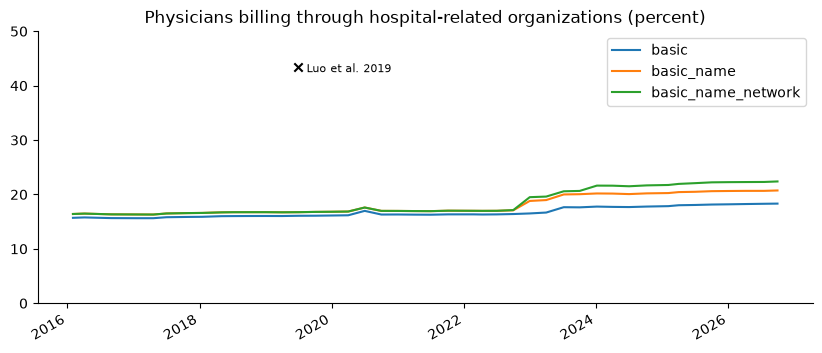

,basic,basic_name,basic_name_network,any_reassignment
as_of_date,,,,
2016-02-01,15.7,16.4,16.4,24.3
2019-04-01,16.0,16.7,16.7,25.4
2022-04-12,16.3,17.0,17.0,27.3
2022-12-30,16.5,18.8,19.5,30.3
2023-03-31,16.7,19.0,19.6,30.5
2025-04-01,18.0,20.4,21.9,32.8
2026-09-29,18.3,20.7,22.4,33.4


In [12]:
# names standardized as Luo et al. describe (upper case, punctuation and legal-form words removed), for the exact
# name match of an organization to a hospital
con.execute(r"""
CREATE OR REPLACE MACRO std_name(s) AS trim(regexp_replace(regexp_replace(regexp_replace(upper(s), '&', ' AND ', 'g'),
    '[^A-Z0-9 ]', ' ', 'g'),
    '\b(THE|INC|INCORPORATED|LLC|L L C|LLP|LP|PC|PA|PLLC|CORP|CORPORATION|CO|COMPANY|LTD)\b', ' ', 'g'))
""")
con.execute("CREATE OR REPLACE MACRO squash(s) AS regexp_replace(std_name(s), ' +', ' ', 'g')")
con.execute(f"""
CREATE OR REPLACE TABLE org_hospital_q AS
WITH oq AS (SELECT q.as_of_date, o.pac_id, o.hospital, squash(o.org_name) AS nm
            FROM quarters q JOIN organization o ON o.effective_date <= q.as_of_date AND (o.end_date IS NULL OR o.end_date > q.as_of_date)),
hosp_names AS (   -- POS hospital names, and from 2022 the hospital enrollments' legal and doing-business-as names
    SELECT q.as_of_date, squash(h.fac_name) AS nm FROM quarters q
    JOIN hospital h ON h.effective_date <= q.as_of_date AND (h.end_date IS NULL OR h.end_date > q.as_of_date)
    UNION
    SELECT q.as_of_date, squash(nm) FROM quarters q
    JOIN (SELECT effective_date, end_date, unnest([org_name, dba_name]) AS nm FROM medicare_facility_enrollment
          WHERE facility_type = 'hospital') e ON e.effective_date <= q.as_of_date AND (e.end_date IS NULL OR e.end_date > q.as_of_date)),
fq AS (SELECT q.as_of_date, m.node_id AS pac_id, f.n_hospitals > 0 AS firm_hospital
       FROM quarters q
       JOIN firm_member m ON m.node_type = 'pac' AND m.effective_date <= q.as_of_date AND (m.end_date IS NULL OR m.end_date > q.as_of_date)
       JOIN firm f ON f.firm_id = m.firm_id AND f.effective_date <= q.as_of_date AND (f.end_date IS NULL OR f.end_date > q.as_of_date))
SELECT oq.as_of_date, oq.pac_id, oq.hospital AS basic,
       coalesce(fq.firm_hospital, false) AS network,
       oq.nm IS NOT NULL AND length(oq.nm) >= 8 AND oq.nm IN (SELECT nm FROM hosp_names h WHERE h.as_of_date = oq.as_of_date) AS name_match
FROM oq LEFT JOIN fq USING (as_of_date, pac_id)
""")
luo = con.sql("""
SELECT w.as_of_date,
       100 * sum(w.w_listed) FILTER (WHERE o.basic) / sum(w.w_listed) AS basic,
       100 * sum(w.w_listed) FILTER (WHERE o.basic OR o.name_match) / sum(w.w_listed) AS basic_name,
       100 * sum(w.w_listed) FILTER (WHERE o.basic OR o.name_match OR o.network) / sum(w.w_listed) AS basic_name_network,
       100 * count(DISTINCT w.practitioner_pac_id) FILTER (WHERE o.basic OR o.name_match OR o.network)
           / count(DISTINCT w.practitioner_pac_id) AS any_reassignment
FROM edge_weight w JOIN org_hospital_q o ON o.as_of_date = w.as_of_date AND o.pac_id = w.organization_pac_id
GROUP BY 1 ORDER BY 1""").df().set_index("as_of_date")
ax = luo.drop(columns="any_reassignment").plot(title="Physicians billing through hospital-related organizations (percent)")
ax.scatter(pd.to_datetime(["2019-06-30"]), [43.5], marker="x", color="k", zorder=5)
ax.annotate("Luo et al. 2019", (pd.Timestamp("2019-06-30"), 43.5), textcoords="offset points", xytext=(6, -4), fontsize=8)
ax.set_xlabel(""); ax.set_ylim(0, 50); plt.show()
luo.iloc[[0, 12, 24, 27, 28, 36, -1]].round(1)

**The network and name steps add little, for a reason the sources explain.** In 2019 the name step lifts the basic share from 16.0 to 16.7%; from December 2022, when the hospital enrollment files add legal and doing-business-as names, the name step adds 2.3 points and the network step 0.6 to 1.7 more, to 22.4% in September 2026 (33.4% with any hospital-related reassignment). Luo et al.'s network step finds 29% of their integrated claims through Form 990 Schedule R, which lists every related organization of a nonprofit system, physician practices included; the All Owners files list the owners of hospitals and nursing homes, not the practices a system owns, so the graph's networks reach few physician groups (section 3). The full measure remains out of reach of the public CMS files alone; Schedule R is the missing source.

### The service location measure

Luo et al. compare their measure with the *service location* measure of Neprash et al. (2015): a physician is integrated when 75% or more of their outpatient visits are billed in a hospital outpatient setting. CMS's Medicare Physician & Other Practitioners by Provider and Service files give each NPI's office and outpatient visits (99201-99205, 99211-99215) by place of service, facility or office, for 2015 to 2024; `graph-build --medicare-utilization` writes them per physician:

`src/healthcare_ledger/derived/sql/medicare_volume.sql`, written to `medicare_volume.parquet`:

```sql
-- medicare_volume: a physician's Medicare Part B billing in calendar year Y (CMS's Medicare Physician & Other
-- Practitioners by Provider and Service file, by the practitioner's NPI), on the first quarter on or after 31 December
-- Y: allowed dollars and services, and the office and outpatient evaluation and management visits (99201-99205,
-- 99211-99215) billed in a facility setting (place of service F: a hospital outpatient department or other facility)
-- and in an office (O); facility_em_share is the facility part of those visits
WITH y AS (SELECT DISTINCT year AS y FROM medicare_service),
q AS (SELECT y.y, min(q.as_of_date) AS as_of_date FROM y JOIN quarters q ON q.as_of_date >= make_date(y.y, 12, 31) GROUP BY 1),
pr AS (SELECT q.y, q.as_of_date, p.pac_id, p.npi FROM q
       JOIN practitioner p ON p.effective_date <= q.as_of_date AND (p.end_date IS NULL OR p.end_date > q.as_of_date)
       SEMI JOIN physician_q f ON f.as_of_date = q.as_of_date AND f.pac_id = p.pac_id),
s AS (SELECT year, npi, sum(allowed) AS allowed, sum(services) AS services,
             sum(services) FILTER (WHERE em AND place_of_service = 'F') AS em_facility,
             sum(services) FILTER (WHERE em AND place_of_service = 'O') AS em_office
      FROM (SELECT *, hcpcs IN ('99201', '99202', '99203', '99204', '99205', '99211', '99212', '99213', '99214', '99215') AS em
            FROM medicare_service)
      GROUP BY ALL)
SELECT pr.as_of_date, pr.pac_id AS practitioner_pac_id, s.year, s.allowed, s.services,
       coalesce(s.em_facility, 0) AS em_facility, coalesce(s.em_office, 0) AS em_office,
       coalesce(s.em_facility, 0) / nullif(coalesce(s.em_facility, 0) + coalesce(s.em_office, 0), 0) AS facility_em_share
FROM s JOIN pr ON pr.y = s.year AND pr.npi = s.npi
```

In [13]:
# the service location measure (Neprash et al. 2015, as Luo et al. use it): a physician is integrated when 75 percent or
# more of their office visits are billed in a facility setting, not when 25 percent or less, hybrid between
slm = con.sql("""
SELECT year, count(*) AS physicians_with_visits,
       100 * avg((facility_em_share >= 0.75)::INT) AS integrated,
       100 * avg((facility_em_share > 0.25 AND facility_em_share < 0.75)::INT) AS hybrid
FROM medicare_volume WHERE em_facility + em_office >= 11 GROUP BY 1 ORDER BY 1""").df().set_index("year")
slm.round(1)

,physicians_with_visits,integrated,hybrid
year,,,
2015,360766,16.1,2.3
2016,364216,11.1,2.7
2017,366485,11.5,2.8
2018,368456,11.9,2.9
2019,371482,12.3,3.0
2020,362118,12.0,3.0
2021,365055,12.4,2.9
2022,365700,12.5,2.9
2023,366371,12.4,3.0


In [14]:
# agreement, physician by physician, on the quarter after each year: the tax-id measure (any hospital-related
# organization with weight, w_listed > 0) against the service location measure
agree = con.sql("""
WITH t AS (SELECT w.as_of_date, w.practitioner_pac_id,
                  sum(w.w_listed) FILTER (WHERE o.basic OR o.name_match OR o.network) AS hosp_w
           FROM edge_weight w JOIN org_hospital_q o ON o.as_of_date = w.as_of_date AND o.pac_id = w.organization_pac_id
           GROUP BY 1, 2)
SELECT v.year, count(*) AS physicians,
       100 * avg((coalesce(t.hosp_w, 0) >= 0.75)::INT) FILTER (WHERE v.facility_em_share >= 0.75) AS slm_integrated_also_tax_id,
       100 * avg((v.facility_em_share >= 0.75)::INT) FILTER (WHERE coalesce(t.hosp_w, 0) >= 0.75) AS tax_id_integrated_also_slm,
       100 * avg((v.facility_em_share <= 0.25)::INT) FILTER (WHERE coalesce(t.hosp_w, 0) >= 0.75) AS tax_id_integrated_office_billing
FROM medicare_volume v JOIN t ON t.as_of_date = v.as_of_date AND t.practitioner_pac_id = v.practitioner_pac_id
WHERE v.em_facility + v.em_office >= 11
GROUP BY 1 ORDER BY 1""").df().set_index("year")
agree.round(1)

,physicians,slm_integrated_also_tax_id,tax_id_integrated_also_slm,tax_id_integrated_office_billing
year,,,,
2015,339519,37.4,52.9,43.5
2016,345639,31.4,30.9,63.6
2017,350080,32.7,31.7,62.9
2018,353427,34.0,32.5,62.0
2019,357840,34.4,33.4,60.7
2020,350138,34.1,32.7,60.7
2021,354210,33.9,33.7,60.3
2022,355387,37.0,30.8,63.6
2023,356720,30.0,29.6,64.8


**The service location measure finds fewer integrated physicians and agrees with the tax-id measure on a third.** From 2016, 11 to 12% of physicians with office visits bill three quarters or more of them in a facility setting, and 3% are hybrid. (2015 is higher, 16%: the 2015 file has half again as many office visits in a facility setting as the later years, a break in the file we have not explained.) Physician by physician, 30 to 37% of the service-location-integrated physicians are also integrated by the tax-id measure (75% or more of their weight on hospital-related organizations), and from 2016 29 to 34% of the tax-id-integrated are integrated by service location, while 60 to 65% of them bill their office visits mostly in an office. Luo et al. report the same disagreement: of 9,557 integrated tax ids, the service location measure classified 38% as integrated. The two measures capture different things: a hospital-employed physician practicing in a freestanding office bills with an office place of service.

## 5. Weights: Physician Compare's claims filter

The PPEF reassignment file lists every active reassignment; a physician with four of them may bill through one. `provider_networks.ipynb` spreads such a physician evenly (1/k) and shows that this matches MD-PPAS on aggregates. Physician Compare, now Doctors and Clinicians, listed a clinician under a group only if the pair had Medicare claims in the past 12 months, and Muhlestein and Smith (2016) used exactly those files. The archived quarterly files, March 2014 to December 2022 (docs/METHODOLOGY.md section 7b), are the claims filter the graph lacked.

`edge_weight` carries every weight the sources support for each physician edge; `w_listed` is the claims-filtered one:

`src/healthcare_ledger/derived/sql/edge_weight.sql`, written to `edge_weight.parquet`:

```sql
-- edge_weight: each physician edge with the weights the sources support. w_fractional is 1/k. Where a Doctors and
-- Clinicians vintage covers the quarter and lists the physician, w_listed spreads the physician over the groups CMS
-- lists them under (Medicare claims under the group in the past 12 months) and gives the others 0; elsewhere it is
-- 1/k. listed is NULL when no vintage covers the quarter. w_medicaid is the edge's share of the physician's Medicaid
-- dollars on the quarters medicaid_volume covers, NULL for a physician with none
WITH l AS (SELECT q.as_of_date, r.practitioner_pac_id, r.organization_pac_id FROM quarters q
           JOIN listed_reassignment r ON r.effective_date <= q.as_of_date AND (r.end_date IS NULL OR r.end_date > q.as_of_date)),
covered AS (SELECT DISTINCT as_of_date FROM l),
x AS (SELECT e.*, c.as_of_date IS NOT NULL AS covered, l.organization_pac_id IS NOT NULL AS is_listed
      FROM physician_edge e
      LEFT JOIN covered c USING (as_of_date)
      LEFT JOIN l USING (as_of_date, practitioner_pac_id, organization_pac_id)),
k AS (SELECT *, count(*) FILTER (WHERE is_listed) OVER (PARTITION BY as_of_date, practitioner_pac_id) AS k_listed FROM x),
m AS (SELECT as_of_date, practitioner_pac_id, organization_pac_id, medicaid_paid,
             sum(medicaid_paid) OVER (PARTITION BY as_of_date, practitioner_pac_id) AS physician_paid
      FROM medicaid_volume)
SELECT k.as_of_date, k.practitioner_pac_id, k.organization_pac_id, k.k,
       1.0 / k.k AS w_fractional,
       CASE WHEN k.covered THEN k.is_listed END AS listed,
       k.k_listed,
       CASE WHEN k.covered AND k.k_listed > 0 THEN CASE WHEN k.is_listed THEN 1.0 / k.k_listed ELSE 0 END
            ELSE 1.0 / k.k END AS w_listed,
       CASE WHEN mp.physician_paid > 0 THEN coalesce(m.medicaid_paid, 0) / mp.physician_paid END AS w_medicaid
FROM k
LEFT JOIN m USING (as_of_date, practitioner_pac_id, organization_pac_id)
LEFT JOIN (SELECT DISTINCT as_of_date, practitioner_pac_id, physician_paid FROM m) mp USING (as_of_date, practitioner_pac_id)
```

First, Muhlestein and Smith on their own data. They report the share of physicians in groups of 100 or more rising from 29.6 to 35.1 percent between June 2013 and December 2015, and in groups of nine or fewer falling from 40.1 to 35.3. Their appendix, which defines how a physician in several groups is counted and how a group is sized, was not available to us, so the cell below shows both conventions: a physician spread over their groups (1/k) or placed in their largest, and a group sized by the physicians the file lists under it.

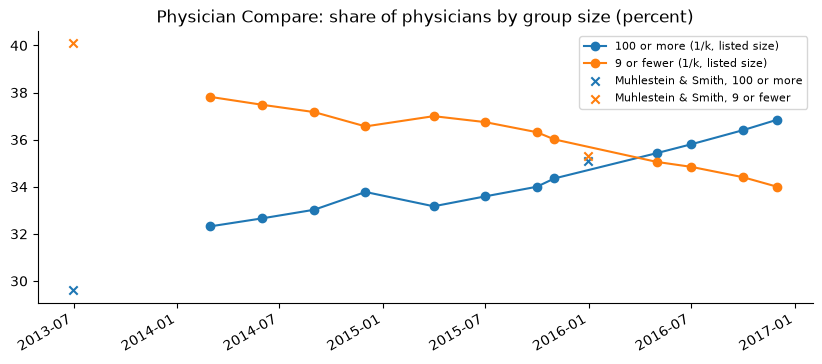

,frac_100_listed,frac_9_listed,frac_100_members,frac_9_members,largest_100_listed,largest_9_listed,physicians
vintage,,,,,,,
2014-03-01,32.3,37.8,34.8,35.6,35.2,35.1,604327
2014-06-01,32.7,37.5,35.3,35.3,35.6,34.8,602967
2014-09-01,33.0,37.2,35.7,34.9,35.9,34.5,603648
2014-12-01,33.8,36.6,36.4,34.3,36.7,33.9,609394
2015-04-01,33.2,37.0,35.5,35.1,35.9,34.5,660993
2015-07-01,33.6,36.7,35.9,34.9,36.4,34.3,661458
2015-10-01,34.0,36.3,36.2,34.4,36.8,33.9,662249
2015-11-01,34.4,36.0,36.6,34.1,37.2,33.6,666073
2016-05-01,35.4,35.1,37.9,33.2,38.6,32.5,682992


In [15]:
# Muhlestein and Smith's own data: Physician Compare, March 2014 to November 2015. A physician is a clinician whose
# primary specialty is a physician specialty (not a nurse practitioner, physician assistant, therapist and so on); a
# group's size is CMS's member count (num_org_mem) or the physicians the file lists under it
NONPHYSICIAN = ("NURSE PRACTITIONER", "PHYSICIAN ASSISTANT", "CERTIFIED REGISTERED NURSE ANESTHETIST", "CLINICAL NURSE SPECIALIST",
                "CERTIFIED NURSE MIDWIFE", "PHYSICAL THERAPIST", "OCCUPATIONAL THERAPIST", "CLINICAL PSYCHOLOGIST",
                "LICENSED CLINICAL SOCIAL WORKER", "CHIROPRACTIC", "OPTOMETRY", "PODIATRY", "AUDIOLOGIST", "REGISTERED DIETITIAN",
                "QUALIFIED SPEECH LANGUAGE PATHOLOGIST", "ANESTHESIOLOGIST ASSISTANT", "CERTIFIED NURSE MIDWIFE (CNM)",
                "ORAL SURGERY (DENTIST ONLY)", "MAXILLOFACIAL SURGERY", "PSYCHOLOGIST", "DENTIST")
vintages = manifest["doctors_clinicians"]["vintages"]
rows = []
for v in [x for x in vintages if x <= "2016-12-31"]:
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE pc AS
    WITH d AS (SELECT DISTINCT npi, org_pac_id, num_org_mem FROM {asof('doctors_clinicians', v)}
               WHERE primary_specialty NOT IN {NONPHYSICIAN}),
    g AS (SELECT org_pac_id, count(DISTINCT npi) AS listed FROM d WHERE org_pac_id IS NOT NULL GROUP BY 1),
    k AS (SELECT npi, greatest(count(DISTINCT org_pac_id), 1) AS k FROM d GROUP BY 1)
    SELECT d.npi, d.org_pac_id, k.k, g.listed, d.num_org_mem FROM d JOIN k USING (npi) LEFT JOIN g USING (org_pac_id)""")
    r = con.sql("""
    WITH largest AS (SELECT npi, max(coalesce(listed, 1)) AS size, max(coalesce(num_org_mem, 1)) AS members FROM pc GROUP BY 1)
    SELECT 100 * sum(1.0 / k) FILTER (WHERE coalesce(listed, 1) >= 100) / sum(1.0 / k) AS frac_100_listed,
           100 * sum(1.0 / k) FILTER (WHERE coalesce(listed, 1) <= 9) / sum(1.0 / k) AS frac_9_listed,
           100 * sum(1.0 / k) FILTER (WHERE coalesce(num_org_mem, 1) >= 100) / sum(1.0 / k) AS frac_100_members,
           100 * sum(1.0 / k) FILTER (WHERE coalesce(num_org_mem, 1) <= 9) / sum(1.0 / k) AS frac_9_members,
           (SELECT 100 * avg((size >= 100)::INT) FROM largest) AS largest_100_listed,
           (SELECT 100 * avg((size <= 9)::INT) FROM largest) AS largest_9_listed,
           (SELECT count(*) FROM largest) AS physicians
    FROM pc""").df()
    rows.append(r.assign(vintage=v))
ms = pd.concat(rows).set_index("vintage")
ms.index = pd.to_datetime(ms.index)
ax = ms[["frac_100_listed", "frac_9_listed"]].rename(columns={
    "frac_100_listed": "100 or more (1/k, listed size)", "frac_9_listed": "9 or fewer (1/k, listed size)"}).plot(
    title="Physician Compare: share of physicians by group size (percent)", marker="o")
ax.scatter(pd.to_datetime(["2013-06-30", "2015-12-31"]), [29.6, 35.1], marker="x", color="C0", zorder=5,
           label="Muhlestein & Smith, 100 or more")
ax.scatter(pd.to_datetime(["2013-06-30", "2015-12-31"]), [40.1, 35.3], marker="x", color="C1", zorder=5,
           label="Muhlestein & Smith, 9 or fewer")
ax.legend(fontsize=8); ax.set_xlabel(""); plt.show()
ms.round(1)

**Physician Compare reproduces Muhlestein and Smith within a point.** Spreading each physician over their groups and sizing a group by the physicians the file lists under it, the November 2015 file has 34.4% of physicians in groups of 100 or more and 36.0% in groups of nine or fewer, against 35.1 and 35.3% in December 2015. The other two conventions bracket it: sizing by CMS's member count, which includes nurse practitioners and other clinicians, gives 36.6 and 34.1%; placing each physician in their largest group gives 37.2 and 33.6%. The trend is the paper's: from March 2014 to November 2015 the share in groups of 100 or more rises 2.1 points (Muhlestein and Smith: 5.5 points from June 2013 to December 2015). The PPEF graph's February 2016 figures (38.5 and 30.2% fractional, `provider_networks.ipynb` section 3) were 3.4 and 5.1 points off; the claims-filtered file closes most of that gap.

In [16]:
# the claims filter, quarter by quarter: how many of the PPEF's physician edges Doctors and Clinicians lists, and
# what the listed weights do to the group-size shares of section 3 of provider_networks.ipynb
listed = con.sql("""
SELECT w.as_of_date,
       100 * avg(w.listed::INT) AS pct_edges_listed,
       100 * avg(w.listed::INT) FILTER (WHERE w.k = 1) AS pct_single_edges_listed,
       100 * avg(w.listed::INT) FILTER (WHERE w.k >= 2) AS pct_multi_edges_listed,
       100 * sum(w.w_fractional) FILTER (WHERE g.physicians >= 100) / sum(w.w_fractional) AS size100_fractional,
       100 * sum(w.w_listed) FILTER (WHERE g.physicians >= 100) / sum(w.w_listed) AS size100_listed_weight,
       100 * sum(w.w_fractional) FILTER (WHERE g.physicians < 10) / sum(w.w_fractional) AS size9_fractional,
       100 * sum(w.w_listed) FILTER (WHERE g.physicians < 10) / sum(w.w_listed) AS size9_listed_weight
FROM edge_weight w JOIN group_size g USING (as_of_date, organization_pac_id)
WHERE w.listed IS NOT NULL GROUP BY 1 ORDER BY 1""").df().set_index("as_of_date")
listed.round(1)

,pct_edges_listed,pct_single_edges_listed,pct_multi_edges_listed,size100_fractional,size100_listed_weight,size9_fractional,size9_listed_weight
as_of_date,,,,,,,
2016-02-01,60.0,80.0,46.7,38.5,39.0,30.2,30.1
2016-04-05,58.4,78.8,45.2,38.8,39.2,30.1,30.1
2016-08-30,59.9,80.2,47.3,39.4,40.2,29.6,29.3
2017-01-19,59.4,80.4,46.8,40.1,41.0,29.1,28.7
2017-04-20,59.1,80.5,46.6,40.3,41.3,29.0,28.5
2017-07-02,59.8,81.5,47.2,40.6,41.7,28.8,28.2
2017-10-30,58.0,79.8,45.6,41.4,42.5,28.3,27.6
2018-01-15,57.1,79.5,44.6,41.8,42.9,28.1,27.5
2018-05-02,48.8,70.2,37.1,41.8,43.4,27.9,26.5


**Physician Compare lists 60% of the PPEF's physician edges in 2016 and 44% by 2022**: four in five single-group physicians' edges but under half of multi-group physicians', falling to 68 and 35%. The PPEF's reassignments accumulate faster than the groups physicians bill through. Weighting by the listed edges raises the share of physicians in groups of 100 or more by 0.5 to 2.2 points and lowers the share in groups of nine or fewer by up to 1.4 points: the reassignments that bill nothing are disproportionately to small groups.

In [17]:
# scored against MD-PPAS: AHRQ's group practice files give, for each tax id, the physicians MD-PPAS assigns it by
# plurality of Part B billing. Each weighting sizes the same tax ids from the graph (the sum of the weight over the
# physicians reassigning to the tax id's associate ids); the error is per tax id, and the share in 100 or more is
# the aggregate section 3 reports
con.execute("""
CREATE OR REPLACE TABLE compendium_q AS
SELECT y.year, arg_min(q.as_of_date, abs(date_diff('day', q.as_of_date, make_date(y.year, 7, 1)))) AS as_of_date
FROM (SELECT DISTINCT year FROM system_link WHERE via = 'group practice file') y CROSS JOIN quarters q GROUP BY 1""")
mdppas = con.sql("""
WITH g AS (SELECT year, compendium_id, any_value(md_ppas_physicians) AS md_ppas
           FROM system_link WHERE node_type = 'organization' AND via = 'group practice file' GROUP BY 1, 2),
e AS (SELECT c.year, l.compendium_id, w.practitioner_pac_id, w.w_fractional, w.w_listed, w.w_medicaid,
             (w.k = 1)::INT AS w_single
      FROM compendium_q c JOIN edge_weight w ON w.as_of_date = c.as_of_date
      JOIN system_link l ON l.year = c.year AND l.node_type = 'organization' AND l.node_id = w.organization_pac_id
       AND l.via = 'group practice file'),
s AS (SELECT year, compendium_id, sum(w_fractional) AS fractional, sum(w_listed) AS listed,
             count(DISTINCT practitioner_pac_id) AS headcount FROM e GROUP BY 1, 2),
j AS (SELECT g.*, coalesce(s.fractional, 0) AS fractional, coalesce(s.listed, 0) AS listed, coalesce(s.headcount, 0) AS headcount
      FROM g LEFT JOIN s USING (year, compendium_id))
SELECT year, count(*) AS tax_ids, sum(md_ppas) AS md_ppas_physicians,
       avg(abs(headcount - md_ppas)) AS mae_headcount, avg(abs(fractional - md_ppas)) AS mae_fractional,
       avg(abs(listed - md_ppas)) AS mae_listed,
       corr(fractional, md_ppas) AS r_fractional, corr(listed, md_ppas) AS r_listed,
       100 * sum(md_ppas) FILTER (WHERE md_ppas >= 100) / sum(md_ppas) AS size100_md_ppas,
       100 * sum(fractional) FILTER (WHERE fractional >= 100) / sum(fractional) AS size100_fractional,
       100 * sum(listed) FILTER (WHERE listed >= 100) / sum(listed) AS size100_listed
FROM j GROUP BY 1 ORDER BY 1""").df().set_index("year")
mdppas.round(2).T

year,2016,2018,2020,2021,2022
tax_ids,41045.00,39058.00,37095.00,36196.00,35438.00
md_ppas_physicians,549750.00,576489.00,596112.00,603276.00,613760.00
mae_headcount,9.36,11.07,14.28,16.78,18.87
mae_fractional,4.34,4.81,4.42,4.89,5.35
mae_listed,3.86,4.10,4.42,3.65,4.07
r_fractional,0.96,0.96,0.98,0.98,0.98
r_listed,0.96,0.97,0.98,0.99,0.99
size100_md_ppas,44.68,48.46,51.75,53.39,54.85
size100_fractional,46.59,49.64,52.69,54.29,55.52
size100_listed,47.16,50.36,52.69,54.88,56.22


**The claims filter improves each tax id's size, not the aggregate.** Against MD-PPAS's count for each tax id AHRQ lists, the listed weights cut the mean absolute error from 4.3 to 3.9 physicians in 2016, 4.8 to 4.1 in 2018, 4.9 to 3.7 in 2021 and 5.4 to 4.1 in 2022, 10 to 25% (no vintage covers the 2020 quarter, so 2020 is unchanged), with the same or a slightly higher correlation (0.96 to 0.99). On the aggregate section 3 of `provider_networks.ipynb` reports, the share in tax ids of 100 or more, the fractional weights are already within 0.7 to 1.9 points of MD-PPAS and the listed weights 1.4 to 2.5: the filter moves weight toward large groups a little more than MD-PPAS's plurality rule does. The claims-filtered weight is the better choice for anything that needs each group's size (concentration, a group's share of a market) and makes no difference to the national size distribution.

## Next steps

Each is a published measure or source the graph is now ready for, and none is done here.

1. **Physician practices in firms.** The All Owners files cover Part A facilities only, so a system's physician groups join its firm only through a shared associate id. IRS Form 990 Schedule R (Luo et al.'s network step) and the Transparency in Coverage tax ids (`research/tic-spike/`) would add the groups a system controls under other tax ids.
2. **Changes of ownership.** CMS's Hospital and SNF Change of Ownership files (2016 on, downloaded with the All Owners files but not loaded) date each acquisition and name buyer and seller; they would date the firm merges of section 3 before 2022 and check them after.
3. **Hospital affiliations as edges.** `hospital_affiliation` (Physician Compare's claims-based hospital CCNs, 2014-2022) supports the affiliation-based integration measures Luo et al. contrast with tax-id measures.
4. **Medicare-volume HHIs.** `medicare_volume` gives each physician's Medicare dollars, the weight the claims-based HHIs of Capps, Dranove and Ody use, for the market concentration of `provider_networks.ipynb` sections 4 and 7.